# Detecção de amastigotas fora do macrófago — experimento 6 (canal Lab puro + batch menor + YOLO11-large)

- Autor: Clésio Gonçalves
- Os experimentos 1-5 convergiram todos para o mesmo patamar de mAP50 (≈ 0.39-0.44), com o experimento 5 (realce CLAHE + YOLO11-medium) obtendo o melhor recall da série. Este experimento (6) testa 3 novas mudanças, conforme solicitado:

## Mudanças

1. **Batch size menor, para mais atualizações de peso** — `batch=4` (em vez de 16). **Atenção a um detalhe técnico importante**: por padrão, o Ultralytics usa acumulação de gradiente para simular um "batch nominal" (`nbs`, padrão 64): com `batch=16` e `nbs=64`, o otimizador só atualiza os pesos a cada 4 mini-batches (`accumulate=round(64/16)=4`) — ou seja, **apenas reduzir o `batch` sozinho não aumenta a frequência de atualização de pesos**, porque a acumulação compensa automaticamente. Para realmente conseguir mais atualizações (objetivo do pedido, já que algumas lâminas têm poucas imagens), este experimento também define `nbs=4` (igual ao `batch`), o que faz `accumulate=1`: o otimizador atualiza os pesos a cada mini-batch, 4x mais vezes por época do que nos experimentos anteriores (que tinham `accumulate=4`).
2. **Espaço de cor Lab usado diretamente como entrada da rede** — diferente do experimento 5 (que aplicava CLAHE no canal L e convertia de volta para RGB), aqui os recortes são convertidos para Lab, o canal L recebe o mesmo realce CLAHE validado no experimento 5, e a imagem final salva é o **empilhamento [L, a, b] sem reconverter para RGB/BGR**. A rede recebe esse array de 3 canais diretamente como entrada (ela não tem noção de "RGB" — só processa 3 canais numéricos). Como consequência, o aumento de dados de cor (`hsv_h/s/v`) do Ultralytics — que assume entrada RGB — não faz sentido aqui e foi **desligado**; os aumentos geométricos (rotação, flip, mixup) do experimento 5 foram mantidos.
3. **Modelo YOLO11-large** (`yolo11l.pt`, ~25M parâmetros).

Mesmos recortes-base (512x512, sem upscaling), mesmas 6 lâminas e mesma divisão de folds dos experimentos anteriores, para comparação direta. **Nota visual**: como a imagem "final" tem os canais L,a,b no lugar de R,G,B, ao exibi-la normalmente (`imshow`) as cores aparecem distorcidas/falsas (núcleos esverdeados) — isso é esperado e não é um erro.

## Resultado

**mAP50 médio: 0.4067 ± 0.1180** — abaixo dos experimentos 1 (0.4391) e 5 (0.4345), no mesmo patamar do experimento 3, e acima apenas do experimento 4. As três mudanças juntas (batch/nbs menor, canal Lab puro, modelo maior) **não melhoraram o resultado agregado**.

**Achado interessante, porém**: a lâmina `leish_3` — pior caso em **todos** os 5 experimentos anteriores (mAP50 entre 0.11 e 0.36, com poucas instâncias de leishmania no dataset original) — teve aqui o **melhor resultado de toda a série para essa lâmina** (precisão 0.6031, mAP50 0.3656). Isso sugere que a combinação de mais atualizações de peso (`accumulate=1`) com o canal Lab pode ajudar especificamente em lâminas com poucos dados, mesmo sem melhorar a média geral — o ganho em `leish_3` foi compensado por perdas em outras lâminas (`leish_4`: 0.151, `leish_8`: 0.283, abaixo da média da série).

**Conclusão acumulada da série de 6 experimentos**: nenhuma combinação testada (tamanho de modelo, cabeça P2, realce de contraste, espaço de cor, batch/nbs, taxa de aprendizado, aumento de dados) produziu uma melhora grande e consistente em todas as lâminas simultaneamente — o que se vê são trocas (uma lâmina melhora, outra piora). Isso reforça que o fator limitante é estrutural: poucas lâminas, com quantidades de dados muito desiguais entre si. O experimento 5 (YOLO11m + realce CLAHE) continua sendo a melhor configuração média da série; a configuração deste experimento 6 pode ser preferível especificamente se o objetivo for melhorar lâminas com poucas instâncias (como `leish_3`), à custa de outras.

## Utilização da GPU

In [1]:
!nvidia-smi

Tue Jun 23 23:46:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.71.05              Driver Version: 595.71.05      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5070 Ti     Off |   00000000:01:00.0 Off |                  N/A |
|  0%   35C    P8             16W /  300W |      14MiB /  16303MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# Importações e parâmetros gerais

In [3]:
import shutil
import yaml
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
from pathlib import Path
from PIL import Image

import torch
from ultralytics import YOLO

import warnings
warnings.filterwarnings('ignore')

# Bloqueia logs de C++ (INFO e WARNING)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_MLIR_ENABLE_MLIR_HAL_TARGET_ EXECUTABLE_DUMP_PATH'] = ''
os.environ['MLIR_CRASH_REPRODUCER_DIRECTORY'] = ''

In [4]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Clésio Gonçalves" --iversions
!python --version
!conda -V

Author: Clésio Gonçalves

PIL        : 12.0.0
cv2        : 4.13.0
matplotlib : 3.10.6
numpy      : 2.3.5
pandas     : 2.3.3
torch      : 2.12.1
ultralytics: 8.4.75
yaml       : 6.0.3

Python 3.13.9


conda 26.1.1


In [5]:
torch.cuda.is_available()

True

## Parâmetros do sistema

In [6]:
# Diretório raiz
diretorio_raiz = Path("/mnt/arquivos/Doutorado")

## Parâmetros do experimento

In [7]:
# Diretório com os recortes (512x512) ORIGINAIS de macrófagos infectados — gerados em pre_processamento_dataset_recortes.ipynb
diretorio_recortes_original = os.path.join(diretorio_raiz, "dataset_recortes_macrofagos_infectados")

# Diretório com os recortes convertidos para Lab (canal L com CLAHE), salvos SEM reconverter para RGB/BGR
diretorio_recortes_lab = os.path.join(diretorio_raiz, "dataset_recortes_macrofagos_infectados_lab")

extensao = '.png'

# Tamanho de treino/inferência = tamanho original do recorte, sem upscaling
tamanho_imagem = 512

# Classes do dataset de recortes (mesma ordem do obj.names)
caminho_obj_names = os.path.join(diretorio_recortes_original, "obj.names")
with open(caminho_obj_names) as f:
    classes_originais = [linha.strip() for linha in f]

# Apenas leishmania FORA do macrófago é a classe de interesse (single-class detector)
nome_classe_interesse = 'leishmania'
indice_classe_interesse = classes_originais.index(nome_classe_interesse)
print(f"Classes originais: {classes_originais}")
print(f"Índice de '{nome_classe_interesse}' (classe de interesse): {indice_classe_interesse}")

# Diretórios de trabalho (dataset YOLO próprio deste experimento, pois as imagens são diferentes - canal Lab)
diretorio_yolo_folds = os.path.join(diretorio_raiz, "yolo_folds_leishmania_lab")
diretorio_runs = os.path.join(diretorio_raiz, "runs_leishmania_kfold_yolo11l_lab")
os.makedirs(diretorio_yolo_folds, exist_ok=True)
os.makedirs(diretorio_runs, exist_ok=True)

# Pesos pré-treinados do YOLO11-large
caminho_pesos_pretreinados = 'yolo11l.pt'

# batch menor + nbs igual ao batch -> accumulate=1 (atualização de pesos a cada mini-batch, não a cada 4)
tamanho_batch = 4

# Hiperparâmetros de treinamento
parametros_treino = dict(
    epochs=150,
    patience=40,
    imgsz=tamanho_imagem,
    batch=tamanho_batch,
    nbs=tamanho_batch,
    device=0,
    seed=42,
    workers=8,
    cos_lr=True,
    single_cls=True,
    verbose=False,
    optimizer='AdamW',
    lr0=0.0005,
    lrf=0.01,
    # aumento de dados geométrico (mantido do experimento 5); aumento de COR desligado,
    # pois a imagem de entrada não é mais RGB (é Lab puro) e o jitter HSV do Ultralytics assume RGB
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,
    degrees=15.0,
    flipud=0.5,
    mixup=0.1,
)

Classes originais: ['Non-macrophages', 'macrophage', 'leishmania', 'inside-macrophage']
Índice de 'leishmania' (classe de interesse): 2


## Pré-processamento: converte os recortes para Lab (canal L com CLAHE), sem reconverter para RGB

In [8]:
# Converte uma imagem BGR para Lab, aplica CLAHE no canal L, e retorna o empilhamento [L_eq, a, b] (SEM reconverter para BGR)
def converte_para_lab_puro(img_bgr, clip_limit=3.0, tile_grid_size=(16, 16)):
    img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    L, a, b = cv2.split(img_lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    L_eq = clahe.apply(L)
    return cv2.merge([L_eq, a, b])


if os.path.isdir(diretorio_recortes_lab):
    print("Os recortes em Lab já foram gerados. Geração ignorada.")
else:
    os.makedirs(diretorio_recortes_lab, exist_ok=True)
    total = 0

    for lamina in sorted(os.listdir(diretorio_recortes_original)):
        pasta_origem = os.path.join(diretorio_recortes_original, lamina)
        if not os.path.isdir(pasta_origem):
            continue

        pasta_destino = os.path.join(diretorio_recortes_lab, lamina)
        os.makedirs(pasta_destino, exist_ok=True)

        for arquivo in sorted(os.listdir(pasta_origem)):
            if arquivo.endswith(extensao):
                img_bgr = cv2.imread(os.path.join(pasta_origem, arquivo))
                img_lab_puro = converte_para_lab_puro(img_bgr)
                cv2.imwrite(os.path.join(pasta_destino, arquivo), img_lab_puro)
                total += 1
            elif arquivo.endswith('.txt'):
                shutil.copy(os.path.join(pasta_origem, arquivo), os.path.join(pasta_destino, arquivo))

    shutil.copy(os.path.join(diretorio_recortes_original, 'obj.names'), diretorio_recortes_lab)
    print(f"{total} imagens convertidas para Lab e salvas em '{diretorio_recortes_lab}'.")

1568 imagens convertidas para Lab e salvas em '/mnt/arquivos/Doutorado/dataset_recortes_macrofagos_infectados_lab'.


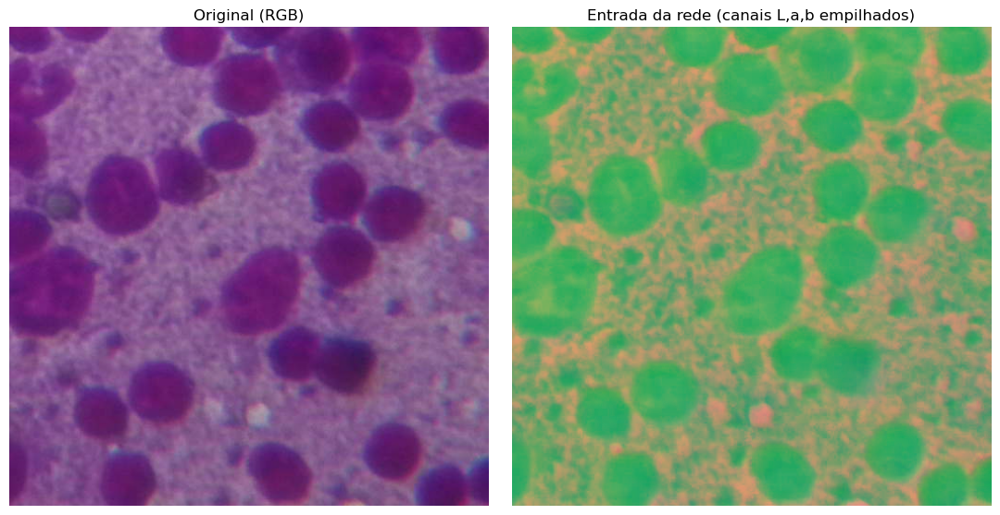

In [9]:
%matplotlib inline
# Nota: a imagem da direita mostra os canais L,a,b interpretados como R,G,B pelo matplotlib -- as cores
# aparecem distorcidas/"falsas" de propósito, pois não é mais uma imagem RGB. É isso que a rede recebe.
lamina_exemplo, arquivo_exemplo = 'leish_7', sorted(os.listdir(os.path.join(diretorio_recortes_original, 'leish_7')))[0]
img_original = cv2.imread(os.path.join(diretorio_recortes_original, lamina_exemplo, arquivo_exemplo))
img_lab_puro = cv2.imread(os.path.join(diretorio_recortes_lab, lamina_exemplo, arquivo_exemplo))

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
axes[0].imshow(cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB))
axes[0].set_title('Original (RGB)')
axes[0].axis('off')
axes[1].imshow(img_lab_puro)  # sem cvtColor: mostra L,a,b "como se fossem" R,G,B
axes[1].set_title('Entrada da rede (canais L,a,b empilhados)')
axes[1].axis('off')
plt.tight_layout()
plt.show()

## Definição dos 6 folds (idêntica aos experimentos anteriores, para comparação direta)

In [10]:
folds = [
    {'fold': 1, 'treino': ['leish_1', 'leish_2', 'leish_7', 'leish_8', 'leish_9'], 'validacao': ['leish_4'], 'teste': ['leish_3', 'leish_5']},
    {'fold': 2, 'treino': ['leish_1', 'leish_3', 'leish_4', 'leish_5', 'leish_9'], 'validacao': ['leish_8'], 'teste': ['leish_2', 'leish_7']},
    {'fold': 3, 'treino': ['leish_2', 'leish_3', 'leish_4', 'leish_5', 'leish_7'], 'validacao': ['leish_9'], 'teste': ['leish_1', 'leish_8']},
    {'fold': 4, 'treino': ['leish_1', 'leish_2', 'leish_3', 'leish_5', 'leish_8'], 'validacao': ['leish_7'], 'teste': ['leish_4', 'leish_9']},
    {'fold': 5, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_8', 'leish_9'], 'validacao': ['leish_2'], 'teste': ['leish_1', 'leish_7']},
    {'fold': 6, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_7', 'leish_9'], 'validacao': ['leish_1'], 'teste': ['leish_2', 'leish_8']},
]

pd.DataFrame(folds).set_index('fold')

,treino,validacao,teste
fold,,,
1,"[leish_1, leish_2, leish_7, leish_8, leish_9]",[leish_4],"[leish_3, leish_5]"
2,"[leish_1, leish_3, leish_4, leish_5, leish_9]",[leish_8],"[leish_2, leish_7]"
3,"[leish_2, leish_3, leish_4, leish_5, leish_7]",[leish_9],"[leish_1, leish_8]"
4,"[leish_1, leish_2, leish_3, leish_5, leish_8]",[leish_7],"[leish_4, leish_9]"
5,"[leish_3, leish_4, leish_5, leish_8, leish_9]",[leish_2],"[leish_1, leish_7]"
6,"[leish_3, leish_4, leish_5, leish_7, leish_9]",[leish_1],"[leish_2, leish_8]"


## Construção da estrutura de dataset YOLO para cada fold (a partir dos recortes em Lab)

In [11]:
# Filtra as anotações de um .txt YOLO, mantendo só a classe de interesse e remapeando-a para o índice 0
def remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse):
    linhas_novas = []
    if os.path.isfile(txt_origem):
        with open(txt_origem) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                partes = linha.split()
                if int(partes[0]) == indice_classe_interesse:
                    linhas_novas.append("0 " + " ".join(partes[1:]))
    return linhas_novas


# Cria link simbólico de uma imagem (já em Lab) e grava o .txt remapeado (classe única) na pasta de destino
def linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse):
    nome_base = os.path.splitext(arquivo)[0]

    img_origem = os.path.join(pasta_origem, arquivo)
    img_destino = os.path.join(pasta_img_destino, arquivo)
    if not os.path.exists(img_destino):
        os.symlink(img_origem, img_destino)

    txt_origem = os.path.join(pasta_origem, f"{nome_base}.txt")
    linhas = remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse)
    with open(os.path.join(pasta_lbl_destino, f"{nome_base}.txt"), 'w') as f:
        f.write("\n".join(linhas))
        if linhas:
            f.write("\n")


# Monta a estrutura YOLO (images/labels) de um fold: treino, validação, teste (agregado) e teste por lâmina
def monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao):
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{fold['fold']}")
    if os.path.isdir(diretorio_fold):
        shutil.rmtree(diretorio_fold)

    for papel, laminas in [('train', fold['treino']), ('val', fold['validacao']), ('test', fold['teste'])]:
        pasta_img_destino = os.path.join(diretorio_fold, 'images', papel)
        pasta_lbl_destino = os.path.join(diretorio_fold, 'labels', papel)
        os.makedirs(pasta_img_destino, exist_ok=True)
        os.makedirs(pasta_lbl_destino, exist_ok=True)

        for lamina in laminas:
            pasta_origem = os.path.join(diretorio_recortes, lamina)

            if papel == 'test':
                # subpasta individual da lâmina (usada no diagnóstico por lâmina do conjunto de teste)
                pasta_img_lamina = os.path.join(diretorio_fold, 'images', 'test_lamina', lamina)
                pasta_lbl_lamina = os.path.join(diretorio_fold, 'labels', 'test_lamina', lamina)
                os.makedirs(pasta_img_lamina, exist_ok=True)
                os.makedirs(pasta_lbl_lamina, exist_ok=True)

            for arquivo in sorted(os.listdir(pasta_origem)):
                if not arquivo.endswith(extensao):
                    continue
                linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse)
                if papel == 'test':
                    linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_lamina, pasta_lbl_lamina, indice_classe_interesse)

    return diretorio_fold


for fold in folds:
    diretorio_fold = monta_dataset_fold(fold, diretorio_recortes_lab, diretorio_yolo_folds, indice_classe_interesse, extensao)
    n_train = len(os.listdir(os.path.join(diretorio_fold, 'images', 'train')))
    n_val = len(os.listdir(os.path.join(diretorio_fold, 'images', 'val')))
    n_test = len(os.listdir(os.path.join(diretorio_fold, 'images', 'test')))
    print(f"Fold {fold['fold']}: treino={n_train} | validação={n_val} | teste={n_test}")

Fold 1: treino=1064 | validação=126 | teste=378
Fold 2: treino=808 | validação=353 | teste=407


Fold 3: treino=911 | validação=208 | teste=449
Fold 4: treino=954 | validação=280 | teste=334


Fold 5: treino=1065 | validação=127 | teste=376
Fold 6: treino=992 | validação=96 | teste=480


## Geração dos arquivos `data.yaml` por fold

In [12]:
# Grava o data.yaml de um fold. Se 'test_split' for informado, aponta o "test" para uma subpasta específica (lâmina única)
def gera_data_yaml(diretorio_fold, nome_classe, caminho_yaml, test_split='test'):
    conteudo = {
        'path': str(diretorio_fold),
        'train': 'images/train',
        'val': 'images/val',
        'test': f'images/{test_split}',
        'nc': 1,
        'names': {0: nome_classe},
    }
    with open(caminho_yaml, 'w') as f:
        yaml.safe_dump(conteudo, f, sort_keys=False, allow_unicode=True)
    return caminho_yaml


caminhos_yaml = {}        # data.yaml agregado (teste = todas as lâminas do fold)
caminhos_yaml_lamina = {} # data.yaml por lâmina de teste, usado no diagnóstico

for fold in folds:
    n = fold['fold']
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{n}")

    caminhos_yaml[n] = gera_data_yaml(
        diretorio_fold, nome_classe_interesse,
        os.path.join(diretorio_fold, 'data.yaml'),
    )

    for lamina in fold['teste']:
        caminhos_yaml_lamina[(n, lamina)] = gera_data_yaml(
            diretorio_fold, nome_classe_interesse,
            os.path.join(diretorio_fold, f'data_test_{lamina}.yaml'),
            test_split=f'test_lamina/{lamina}',
        )

print(f"{len(caminhos_yaml)} data.yaml agregados e {len(caminhos_yaml_lamina)} data.yaml por lâmina de teste gerados.")

6 data.yaml agregados e 12 data.yaml por lâmina de teste gerados.


## Treinamento dos 6 folds (YOLO11-large, canal Lab, batch=4/nbs=4)

Treinamento local na GPU a partir do checkpoint pré-treinado `yolo11l.pt`. Caso o `best.pt` de um fold já exista, o treinamento desse fold é pulado (idempotente).

In [13]:
caminhos_best = {}

for fold in folds:
    n = fold['fold']
    nome_run = f"fold_{n}"
    caminho_best = os.path.join(diretorio_runs, nome_run, 'weights', 'best.pt')

    if os.path.isfile(caminho_best):
        print(f"Fold {n}: pesos já existem em '{caminho_best}'. Treinamento ignorado.")
    else:
        modelo = YOLO(caminho_pesos_pretreinados)
        modelo.train(
            data=caminhos_yaml[n],
            project=diretorio_runs,
            name=nome_run,
            exist_ok=True,
            **parametros_treino,
        )
        print(f"Fold {n}: treinamento concluído. Pesos em '{caminho_best}'.")
        del modelo
        torch.cuda.empty_cache()

    caminhos_best[n] = caminho_best

Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/mnt/arquivos/Doutorado/yolo_folds_leishmania_lab/fold_1/data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fold_1, nbs=4, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=40, perspective=0.0, plots=True, pose=12.0, pretraine

Overriding class names with single class.


Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


  0                  -1  1      1856  ultralytics.nn.modules.conv.Conv             [3, 64, 3, 2]                 


... (54,092 outputs left out)

                   all         96        831      0.505      0.445      0.421       0.18


Speed: 0.1ms preprocess, 2.3ms inference, 0.0ms loss, 0.3ms postprocess per image


Results saved to /mnt/arquivos/Doutorado/runs_leishmania_kfold_yolo11l_lab/fold_6


Fold 6: treinamento concluído. Pesos em '/mnt/arquivos/Doutorado/runs_leishmania_kfold_yolo11l_lab/fold_6/weights/best.pt'.


## Avaliação no conjunto de teste — agregada por fold

In [14]:
# Extrai as métricas de detecção relevantes de um resultado de model.val()
def extrai_metricas(resultado_val):
    rd = resultado_val.results_dict
    return {
        'precisao': rd.get('metrics/precision(B)', float('nan')),
        'recall': rd.get('metrics/recall(B)', float('nan')),
        'mAP50': rd.get('metrics/mAP50(B)', float('nan')),
        'mAP50-95': rd.get('metrics/mAP50-95(B)', float('nan')),
    }


linhas_metricas_fold = []

for fold in folds:
    n = fold['fold']
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminhos_yaml[n], split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['laminas_teste'] = ", ".join(fold['teste'])
    linhas_metricas_fold.append(metricas)

df_metricas_fold = pd.DataFrame(linhas_metricas_fold).set_index('fold')
df_metricas_fold = df_metricas_fold[['laminas_teste', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_fold

Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


YOLO11l summary (fused): 191 layers, 25,280,083 parameters, 0 gradients, 86.6 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5870.4±751.9 MB/s, size: 309.6 KB)


val: Scanning /mnt/arquivos/Doutorado/yolo_folds_leishmania_lab/fold_1/labels/test... 198 images, 14 backgrounds, 0 corrupt: 52% ━━━━━━────── 198/378 591.9it/s 0.1s<0.3s

val: Scanning /mnt/arquivos/Doutorado/yolo_folds_leishmania_lab/fold_1/labels/test... 378 images, 52 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 378/378 2.0Kit/s 0.2s

val: New cache created: /mnt/arquivos/Doutorado/yolo_folds_leishmania_lab/fold_1/labels/test.cache


... (122 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 14.4it/s 2.1s

                   all        480       1634      0.331      0.431      0.295      0.112


Speed: 0.1ms preprocess, 3.4ms inference, 0.0ms loss, 0.2ms postprocess per image


,laminas_teste,precisao,recall,mAP50,mAP50-95
fold,,,,,
1,"leish_3, leish_5",0.527582,0.569166,0.514667,0.181936
2,"leish_2, leish_7",0.534314,0.544070,0.484437,0.179686
3,"leish_1, leish_8",0.326346,0.383434,0.261141,0.093732
4,"leish_4, leish_9",0.368731,0.492116,0.353653,0.134409
5,"leish_1, leish_7",0.603183,0.522305,0.531142,0.188788
6,"leish_2, leish_8",0.330598,0.431457,0.295028,0.111528


In [15]:
# Média aritmética e desvio padrão de cada métrica entre os 6 folds
resumo_metricas = df_metricas_fold[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std']).T
resumo_metricas.columns = ['média', 'desvio_padrão']
resumo_metricas.round(4)

,média,desvio_padrão
precisao,0.4485,0.1206
recall,0.4904,0.0707
mAP50,0.4067,0.1180
mAP50-95,0.1483,0.0407


## Comparação com os experimentos anteriores

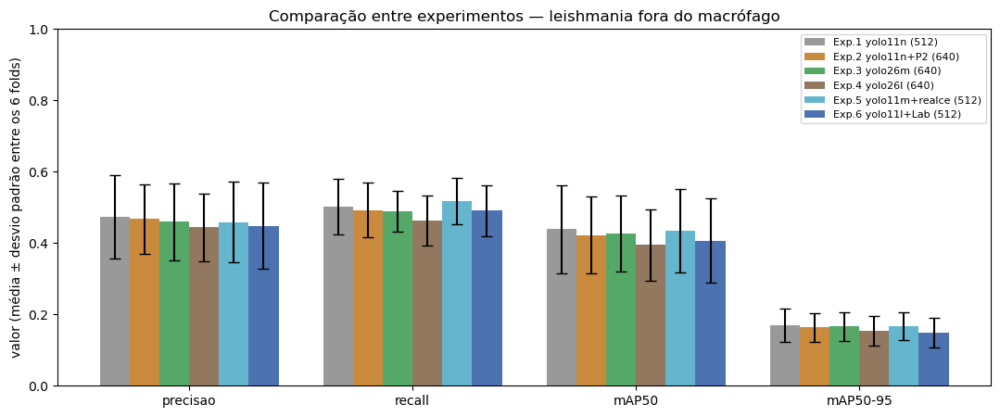

In [16]:
%matplotlib inline
# Médias e desvios padrão dos experimentos anteriores, copiados aqui apenas para referência visual (mesmos 6 folds)
resumo_experimentos_anteriores = {
    'Exp.1 yolo11n (512)': pd.Series({'precisao': 0.4735, 'recall': 0.5012, 'mAP50': 0.4391, 'mAP50-95': 0.1695}),
    'Exp.2 yolo11n+P2 (640)': pd.Series({'precisao': 0.4672, 'recall': 0.4922, 'mAP50': 0.4226, 'mAP50-95': 0.1640}),
    'Exp.3 yolo26m (640)': pd.Series({'precisao': 0.4595, 'recall': 0.4894, 'mAP50': 0.4272, 'mAP50-95': 0.1659}),
    'Exp.4 yolo26l (640)': pd.Series({'precisao': 0.4442, 'recall': 0.4632, 'mAP50': 0.3943, 'mAP50-95': 0.1538}),
    'Exp.5 yolo11m+realce (512)': pd.Series({'precisao': 0.4581, 'recall': 0.5170, 'mAP50': 0.4345, 'mAP50-95': 0.1670}),
}
desvios_experimentos_anteriores = {
    'Exp.1 yolo11n (512)': pd.Series({'precisao': 0.1164, 'recall': 0.0780, 'mAP50': 0.1229, 'mAP50-95': 0.0457}),
    'Exp.2 yolo11n+P2 (640)': pd.Series({'precisao': 0.0981, 'recall': 0.0763, 'mAP50': 0.1083, 'mAP50-95': 0.0405}),
    'Exp.3 yolo26m (640)': pd.Series({'precisao': 0.1079, 'recall': 0.0567, 'mAP50': 0.1068, 'mAP50-95': 0.0396}),
    'Exp.4 yolo26l (640)': pd.Series({'precisao': 0.0946, 'recall': 0.0705, 'mAP50': 0.1000, 'mAP50-95': 0.0417}),
    'Exp.5 yolo11m+realce (512)': pd.Series({'precisao': 0.1132, 'recall': 0.0652, 'mAP50': 0.1175, 'mAP50-95': 0.0391}),
}

metricas_plot = ['precisao', 'recall', 'mAP50', 'mAP50-95']
nomes_exp = list(resumo_experimentos_anteriores.keys()) + ['Exp.6 yolo11l+Lab (512)']
medias_exp = [resumo_experimentos_anteriores[n][metricas_plot] for n in resumo_experimentos_anteriores] + [resumo_metricas.loc[metricas_plot, 'média']]
desvios_exp = [desvios_experimentos_anteriores[n][metricas_plot] for n in desvios_experimentos_anteriores] + [resumo_metricas.loc[metricas_plot, 'desvio_padrão']]

x = np.arange(len(metricas_plot))
n_exp = len(nomes_exp)
largura = 0.8 / n_exp
cores = ['#999999', '#c98a3e', '#55a868', '#937860', '#64b5cd', '#4C72B0']

fig, ax = plt.subplots(figsize=(13, 5))
for i, (nome, media, desvio) in enumerate(zip(nomes_exp, medias_exp, desvios_exp)):
    deslocamento = (i - (n_exp - 1) / 2) * largura
    ax.bar(x + deslocamento, media, largura, yerr=desvio, capsize=4, label=nome, color=cores[i % len(cores)])

ax.set_xticks(x)
ax.set_xticklabels(metricas_plot)
ax.set_ylim(0, 1)
ax.set_ylabel('valor (média ± desvio padrão entre os 6 folds)')
ax.set_title('Comparação entre experimentos — leishmania fora do macrófago')
ax.legend(loc='upper right', fontsize=8)
plt.show()

## Diagnóstico por lâmina (conjunto de teste)

In [17]:
linhas_metricas_lamina = []

for (n, lamina), caminho_yaml_lamina in caminhos_yaml_lamina.items():
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminho_yaml_lamina, split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['lamina'] = lamina
    linhas_metricas_lamina.append(metricas)

df_metricas_lamina = pd.DataFrame(linhas_metricas_lamina)[['lamina', 'fold', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_lamina.sort_values(['lamina', 'fold']).reset_index(drop=True)

Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


YOLO11l summary (fused): 191 layers, 25,280,083 parameters, 0 gradients, 86.6 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4725.2±418.4 MB/s, size: 316.2 KB)


val: Scanning /mnt/arquivos/Doutorado/yolo_folds_leishmania_lab/fold_1/labels/test_lamina/leish_3... 17 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17 1.8Kit/s 0.0s

val: New cache created: /mnt/arquivos/Doutorado/yolo_folds_leishmania_lab/fold_1/labels/test_lamina/leish_3.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 2.4it/s 0.1s<0.4s

... (168 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 15.0it/s 1.5s

                   all        353        992      0.309       0.44      0.285      0.107


Speed: 0.1ms preprocess, 3.5ms inference, 0.0ms loss, 0.2ms postprocess per image


,lamina,fold,precisao,recall,mAP50,mAP50-95
0,leish_1,3,0.478123,0.375451,0.376812,0.152152
1,leish_1,5,0.574122,0.379061,0.429264,0.168057
2,leish_2,2,0.354402,0.450156,0.316851,0.117997
3,leish_2,6,0.381281,0.401230,0.317687,0.122400
4,leish_3,1,0.603074,0.300000,0.365611,0.157646
5,leish_4,4,0.204168,0.357615,0.151048,0.054903
6,leish_5,1,0.533595,0.570370,0.519880,0.183666
7,leish_7,2,0.624954,0.570740,0.580230,0.215502
8,leish_7,5,0.628528,0.590451,0.593325,0.207929
9,leish_8,3,0.343191,0.406250,0.280628,0.095471


In [18]:
# Resumo por lâmina: média e desvio padrão entre as vezes em que a lâmina caiu no teste (1 ou 2 folds)
resumo_lamina = df_metricas_lamina.groupby('lamina')[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std', 'count'])
resumo_lamina.round(4)

precisao                recall                 mAP50                \
            mean     std count    mean     std count    mean     std count   
lamina                                                                       
leish_1   0.5261  0.0679     2  0.3773  0.0026     2  0.4030  0.0371     2   
leish_2   0.3678  0.0190     2  0.4257  0.0346     2  0.3173  0.0006     2   
leish_3   0.6031     NaN     1  0.3000     NaN     1  0.3656     NaN     1   
leish_4   0.2042     NaN     1  0.3576     NaN     1  0.1510     NaN     1   
leish_5   0.5336     NaN     1  0.5704     NaN     1  0.5199     NaN     1   
leish_7   0.6267  0.0025     2  0.5806  0.0139     2  0.5868  0.0093     2   
leish_8   0.3260  0.0243     2  0.4233  0.0241     2  0.2826  0.0028     2   
leish_9   0.4096     NaN     1  0.5387     NaN     1  0.4304     NaN     1   

        mAP50-95                
            mean     std count  
lamina                          
leish_1   0.1601  0.0112     2  
leish_2   0.1202  0.0031     2  
leish_3   0.1576     NaN     1  
leish_4   0.0549     NaN     1  
leish_5   0.1837     NaN     1  
leish_7   0.2117  0.0054     2  
leish_8   0.1011  0.0079     2  
leish_9   0.1648     NaN     1

## Comparação visual: anotação do especialista vs. detecção da YOLO

Em cada imagem: caixas **amarelas** = anotação original do especialista (classe `leishmania`, remapeada); caixas **vermelhas** = detecções do modelo (com confiança). Amostras da lâmina com melhor e da lâmina com pior mAP50 no diagnóstico acima. **As cores de fundo aparecem distorcidas** porque a imagem mostrada é o array Lab puro (ver nota na seção de pré-processamento).

In [19]:
# Lê as caixas (em pixels) de um .txt YOLO (classe única já remapeada)
def le_boxes_pixel(txt_path, largura, altura):
    boxes = []
    if os.path.isfile(txt_path):
        with open(txt_path) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                _, xc, yc, w, h = map(float, linha.split())
                boxes.append((xc * largura, yc * altura, w * largura, h * altura))
    return boxes


# Desenha, sobre o mesmo eixo, as caixas do especialista (amarelo) e as detecções do modelo (vermelho)
def desenha_comparacao(eixo, caminho_imagem, caminho_label, modelo, conf=0.25):
    img_lab_puro = cv2.imread(caminho_imagem)  # array L,a,b "cru" -- mostrado sem cvtColor (cores distorcidas de propósito)
    altura, largura = img_lab_puro.shape[:2]
    eixo.imshow(img_lab_puro)

    gt_boxes = le_boxes_pixel(caminho_label, largura, altura)
    for xc, yc, w, h in gt_boxes:
        eixo.add_patch(patches.Rectangle((xc - w / 2, yc - h / 2), w, h, linewidth=1.5, edgecolor='yellow', facecolor='none'))

    resultado = modelo.predict(caminho_imagem, conf=conf, imgsz=tamanho_imagem, verbose=False)[0]
    for caixa in resultado.boxes:
        x1, y1, x2, y2 = caixa.xyxy[0].tolist()
        confianca = float(caixa.conf[0])
        eixo.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.5, edgecolor='red', facecolor='none'))
        eixo.text(x1, max(y1 - 4, 0), f"{confianca:.2f}", color='red', fontsize=7, va='bottom')

    eixo.set_title(f"{os.path.basename(caminho_imagem)}\nespecialista={len(gt_boxes)} | YOLO={len(resultado.boxes)}", fontsize=8)
    eixo.axis('off')


def fold_para_lamina(lamina):
    for fold in folds:
        if lamina in fold['teste']:
            return fold['fold']

Melhor lâmina (mAP50): leish_7 | Pior lâmina (mAP50): leish_4


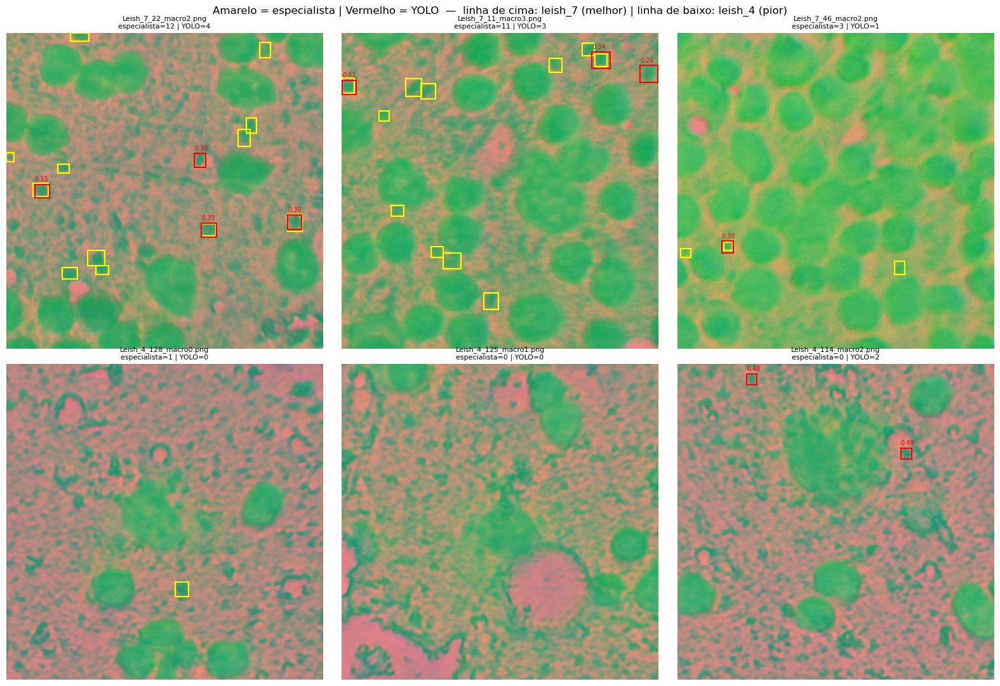

In [20]:
%matplotlib inline
melhor_lamina = resumo_lamina[('mAP50', 'mean')].idxmax()
pior_lamina = resumo_lamina[('mAP50', 'mean')].idxmin()
print(f"Melhor lâmina (mAP50): {melhor_lamina} | Pior lâmina (mAP50): {pior_lamina}")

cache_modelos = {}
def obter_modelo(n_fold):
    if n_fold not in cache_modelos:
        cache_modelos[n_fold] = YOLO(caminhos_best[n_fold])
    return cache_modelos[n_fold]

amostras_comparacao = []
random.seed(42)
for lamina in [melhor_lamina, pior_lamina]:
    n_fold = fold_para_lamina(lamina)
    pasta_img = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'images', 'test_lamina', lamina)
    pasta_lbl = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'labels', 'test_lamina', lamina)
    imagens = sorted(f for f in os.listdir(pasta_img) if f.endswith(extensao))
    escolhidas = random.sample(imagens, min(3, len(imagens)))
    for img_nome in escolhidas:
        amostras_comparacao.append((n_fold, lamina, pasta_img, pasta_lbl, img_nome))

fig, eixos = plt.subplots(2, 3, figsize=(16, 11))
for eixo, (n_fold, lamina, pasta_img, pasta_lbl, img_nome) in zip(eixos.ravel(), amostras_comparacao):
    modelo = obter_modelo(n_fold)
    nome_base = os.path.splitext(img_nome)[0]
    desenha_comparacao(eixo, os.path.join(pasta_img, img_nome), os.path.join(pasta_lbl, f"{nome_base}.txt"), modelo)

fig.suptitle(f"Amarelo = especialista | Vermelho = YOLO  —  linha de cima: {melhor_lamina} (melhor) | linha de baixo: {pior_lamina} (pior)")
plt.tight_layout()
plt.show()